# Ajuste por familias de modelos

BolsaLAB · Grupo 10


In [1]:
# False: lee reports/tuning.csv. True: vuelve a correr los pasos 1 y 2 (unos 2 minutos).
RECALCULAR = False

In [ ]:
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

import json

import matplotlib.pyplot as plt
import pandas as pd
from xgboost import XGBClassifier

from bolsalab.b  import RANDOM_STATE
from bolsalab.modeling import tuning
from bolsalab.modeling.early_stopping import EarlyStoppingBooster
from bolsalab.modeling.train import BENCHMARK_FILE, TRAINING_FILE, split_data

BLUE = "#2a78d6"
ORANGE = "#eb6834"
GRAY = "#555555"
UMBRAL = 0.6636
LIMITE_BRECHA = 0.03


def estilo(ax):
    for lado in ("top", "right"):
        ax.spines[lado].set_visible(False)
    ax.grid(color="#e5e5e2", linewidth=0.8)
    ax.set_axisbelow(True)


table = pd.read_parquet(TRAINING_FILE)
X_train, X_test, y_train, y_test = split_data(table)

if RECALCULAR:
    tuning.run_step(1, X_train, y_train, rerun=True)
    tuning.run_step(2, X_train, y_train, rerun=True)

resultados = pd.read_csv(tuning.TUNING_FILE)
benchmark = pd.read_csv(BENCHMARK_FILE).set_index("model")

## 0. Datos y validación


In [3]:
pd.DataFrame({
    "Personas": [len(table), len(X_train), len(X_test)],
    "Vendieron": [pd.concat([y_train, y_test]).mean(), y_train.mean(), y_test.mean()],
    "Uso": ["", "Ajuste y validación", "Prueba final (no se usa aquí)"],
}, index=pd.Index(["Total", "Entrenamiento 80 %", "Prueba 20 %"], name="Conjunto")).style.format(
    {"Personas": "{:,}", "Vendieron": "{:.1%}"})

,Personas,Vendieron,Uso
Conjunto,,,
Total,"54,704",19.9%,
Entrenamiento 80 %,"43,763",19.9%,Ajuste y validación
Prueba 20 %,"10,941",19.9%,Prueba final (no se usa aquí)


In [4]:
externo = len(X_train) * 4 // 5
interno = externo * 2 // 3
pd.DataFrame({
    "Particiones": [5, 3, 1],
    "Personas que entrenan": [externo, interno, round(externo * 0.9)],
    "Personas que evalúan": [len(X_train) - externo, externo - interno, round(externo * 0.1)],
    "Uso": ["Medir el modelo", "Elegir hiperparámetros", "Decidir cuántos árboles"],
}, index=pd.Index(["Externa", "Interna", "Parada temprana"], name="Nivel")).style.format(
    {"Personas que entrenan": "{:,}", "Personas que evalúan": "{:,}"})

,Particiones,Personas que entrenan,Personas que evalúan,Uso
Nivel,,,,
Externa,5,"35,010","8,753",Medir el modelo
Interna,3,"23,340","11,670",Elegir hiperparámetros
Parada temprana,1,"31,509","3,501",Decidir cuántos árboles


## 1. Punto de partida: comparación oficial


In [5]:
nombres = {"trivial": "Naive", "logistic": "Regresión logística", "random_forest": "Random Forest",
           "xgboost": "XGBoost", "lightgbm": "LightGBM", "catboost": "CatBoost",
           "neural_net": "Red neuronal"}
oficial = benchmark[["auroc", "auroc_sd", "auprc", "brier", "calibration_slope"]].rename(index=nombres)
oficial.columns = ["AUROC", "±", "AUPRC", "Brier", "Pendiente"]
oficial.index.name = "Modelo"
oficial.round(4)

,AUROC,±,AUPRC,Brier,Pendiente
Modelo,,,,,
Naive,0.5000,0.0000,0.1987,0.1592,0.6605
Regresión logística,0.6456,0.0023,0.3047,0.1523,0.9995
Random Forest,0.6573,0.0037,0.3304,0.1507,1.2284
XGBoost,0.6601,0.0035,0.3307,0.1503,1.0556
LightGBM,0.6600,0.0036,0.3306,0.1503,1.0546
CatBoost,0.6613,0.0039,0.3320,0.1502,1.0956
Red neuronal,0.6346,0.0179,0.3032,0.1532,0.8230


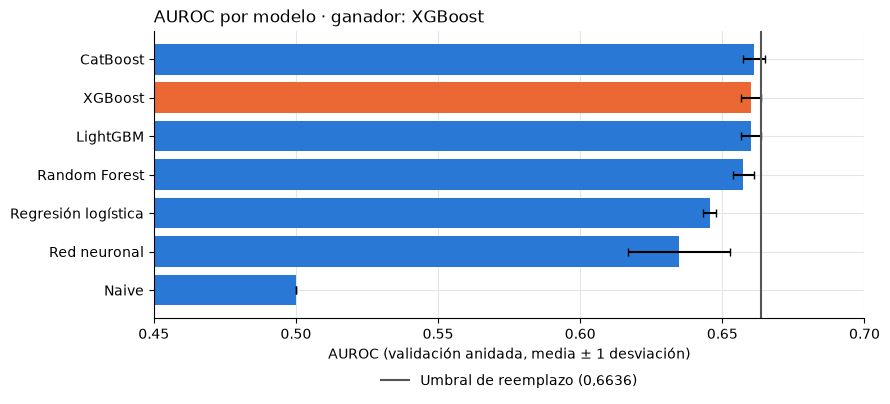

In [6]:
orden = oficial.sort_values("AUROC")
fig, ax = plt.subplots(figsize=(9, 4.2))
colores = [ORANGE if m == "XGBoost" else BLUE for m in orden.index]
ax.barh(orden.index, orden["AUROC"], xerr=orden["±"], color=colores, capsize=3)
ax.axvline(UMBRAL, color=GRAY, linewidth=1.5, label="Umbral de reemplazo (0,6636)")
ax.set_xlim(0.45, 0.70)
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.15))
ax.set_xlabel("AUROC (validación anidada, media ± 1 desviación)")
ax.set_title("AUROC por modelo · ganador: XGBoost", loc="left")
estilo(ax)
plt.tight_layout()
plt.show()

## 2. Paso 1 · Parada temprana


| Parámetro | Antes | Ahora |
|---|---|---|
| Número de árboles | 300 fijos | Lo decide el modelo (tope 2.000) |
| Paciencia | — | 50 árboles sin mejorar |
| Validación para parar | — | 10 % del entrenamiento de cada partición |
| `learning_rate` | 0,03; 0,1 | 0,03; 0,1 |
| Profundidad | 3; 5 (CatBoost 4; 6) | 3; 5 (CatBoost 4; 6) |

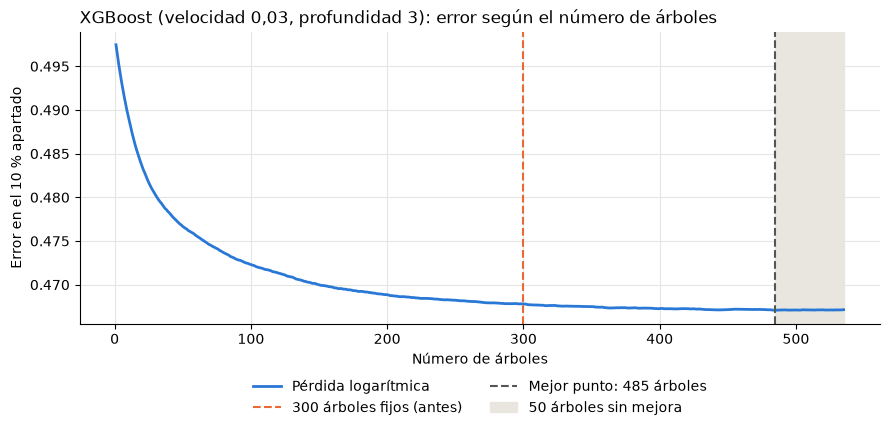

Error con 300 árboles: 0.4678 · con 485: 0.4671


In [7]:
demo = EarlyStoppingBooster(
    XGBClassifier(n_estimators=tuning.MAX_TREES, learning_rate=0.03, max_depth=3,
                  random_state=RANDOM_STATE),
    validation_fraction=tuning.VALIDATION_FRACTION, patience=tuning.PATIENCE,
).fit(X_train, y_train)
error = demo.estimator_.evals_result()["validation_0"]["logloss"]

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(range(1, len(error) + 1), error, color=BLUE, linewidth=2, label="Pérdida logarítmica")
ax.axvline(300, color=ORANGE, linestyle="--", linewidth=1.5, label="300 árboles fijos (antes)")
ax.axvline(demo.n_trees_, color=GRAY, linestyle="--", linewidth=1.5,
           label=f"Mejor punto: {demo.n_trees_} árboles")
ax.axvspan(demo.n_trees_, len(error), color="#e8e6df", label="50 árboles sin mejora")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2)
ax.set_xlabel("Número de árboles")
ax.set_ylabel("Error en el 10 % apartado")
ax.set_title("XGBoost (velocidad 0,03, profundidad 3): error según el número de árboles", loc="left")
estilo(ax)
plt.tight_layout()
plt.show()

print(f"Error con 300 árboles: {error[299]:.4f} · con {demo.n_trees_}: {error[demo.n_trees_ - 1]:.4f}")

In [8]:
paso1 = resultados[resultados["step"] == 1].copy()
paso1["modelo"] = paso1["experiment"].str.split("|").str[0]

tabla = pd.DataFrame({
    "AUROC antes": paso1["modelo"].map(benchmark["auroc"]).values,
    "AUROC ahora": paso1["auroc"].values,
    "±": paso1["auroc_sd"].values,
    "Pendiente antes": paso1["modelo"].map(benchmark["calibration_slope"]).values,
    "Pendiente ahora": paso1["calibration_slope"].values,
    "Brecha": paso1["overfit_gap"].values,
}, index=paso1["modelo"].map(nombres).rename("Modelo"))
tabla.round(4)

,AUROC antes,AUROC ahora,±,Pendiente antes,Pendiente ahora,Brecha
Modelo,,,,,,
XGBoost,0.6601,0.6594,0.0032,1.0556,0.9881,0.0223
LightGBM,0.6600,0.6595,0.0033,1.0546,0.9993,0.0212
CatBoost,0.6613,0.6612,0.0042,1.0956,1.0630,0.0205


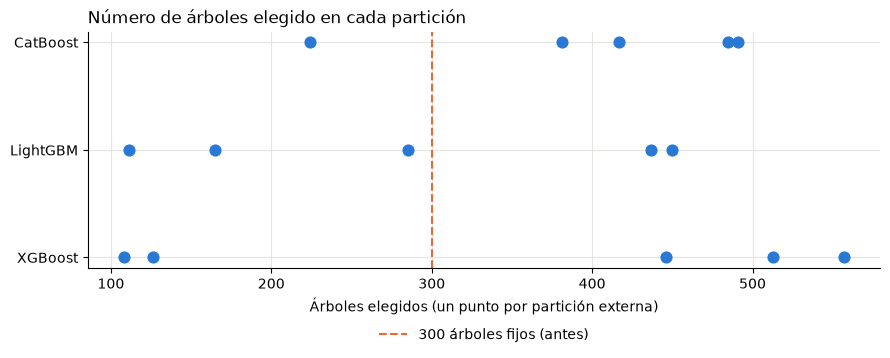

In [9]:
fig, ax = plt.subplots(figsize=(9, 3.8))
for fila, detalle in enumerate(paso1["fold_detail"]):
    arboles = json.loads(detalle)
    ax.scatter(arboles, [fila] * len(arboles), color=BLUE, s=60, zorder=3)
ax.axvline(300, color=ORANGE, linestyle="--", linewidth=1.5, label="300 árboles fijos (antes)")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.2))
ax.set_yticks(range(len(paso1)), paso1["modelo"].map(nombres))
ax.set_xlabel("Árboles elegidos (un punto por partición externa)")
ax.set_title("Número de árboles elegido en cada partición", loc="left")
estilo(ax)
plt.tight_layout()
plt.show()

## 3. Paso 2 · Poda


| Parámetro | XGBoost | LightGBM |
|---|---|---|
| Ganancia mínima por corte | `gamma`: 0; 0,5; 1; 2 | `min_split_gain`: 0; 0,5; 1; 2 |
| Castigo a hojas extremas | `reg_lambda`: 1; 5; 10 | `reg_lambda`: 0; 5; 10 |
| `learning_rate` | 0,03; 0,1 | 0,03; 0,1 |
| Profundidad | 3 | 3 |
| Árboles | Parada temprana (paso 1) | Parada temprana (paso 1) |

In [10]:
paso2 = resultados[resultados["step"] == 2]
elecciones = []
for experimento, parametros in zip(paso2["experiment"], paso2["best_params"]):
    for particion, p in enumerate(json.loads(parametros), start=1):
        limpio = {k.split("__")[-1]: v for k, v in p.items() if not k.endswith("max_depth")}
        elecciones.append({"Modelo": nombres[experimento.split("|")[0]], "Partición": particion, **limpio})
pd.DataFrame(elecciones).set_index(["Modelo", "Partición"]).fillna("—")

gamma  learning_rate  reg_lambda min_split_gain
Modelo   Partición                                                
XGBoost  1           0.0           0.03          10              —
         2           0.5           0.03          10              —
         3           1.0           0.10          10              —
         4           1.0           0.03          10              —
         5           0.5           0.10          10              —
LightGBM 1             —           0.10           5            0.5
         2             —           0.03          10            0.0
         3             —           0.10          10            0.0
         4             —           0.10          10            0.5
         5             —           0.10           5            0.5

In [11]:
vista = resultados.set_index("experiment")[
    ["auroc", "auroc_sd", "overfit_gap", "calibration_slope"]].round(4)
vista.columns = ["AUROC", "±", "Brecha", "Pendiente"]
vista.index.name = "Prueba"
vista.loc[["xgboost|parada_temprana", "xgboost|poda", "lightgbm|parada_temprana", "lightgbm|poda"]]

,AUROC,±,Brecha,Pendiente
Prueba,,,,
xgboost|parada_temprana,0.6594,0.0032,0.0223,0.9881
xgboost|poda,0.6595,0.0037,0.0194,1.0096
lightgbm|parada_temprana,0.6595,0.0033,0.0212,0.9993
lightgbm|poda,0.6601,0.0032,0.0191,1.0050


## 4. Resumen frente al umbral de reemplazo


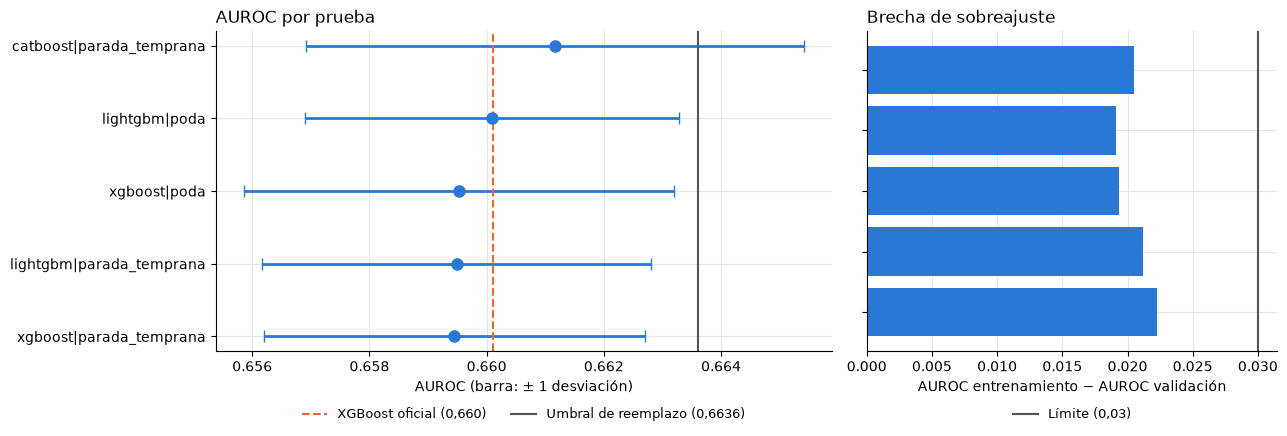

In [12]:
orden = resultados.sort_values("auroc")

fig, (izq, der) = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [3, 2]})

izq.errorbar(orden["auroc"], range(len(orden)), xerr=orden["auroc_sd"],
             fmt="o", color=BLUE, markersize=8, capsize=4, linewidth=2)
izq.axvline(benchmark.loc["xgboost", "auroc"], color=ORANGE, linestyle="--",
            label="XGBoost oficial (0,660)")
izq.axvline(UMBRAL, color=GRAY, linewidth=1.5, label="Umbral de reemplazo (0,6636)")
izq.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=2, fontsize=9)
izq.set_yticks(range(len(orden)), orden["experiment"])
izq.set_xlabel("AUROC (barra: ± 1 desviación)")
izq.set_title("AUROC por prueba", loc="left")
estilo(izq)

der.barh(range(len(orden)), orden["overfit_gap"], color=BLUE)
der.axvline(LIMITE_BRECHA, color=GRAY, linewidth=1.5, label="Límite (0,03)")
der.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.14), fontsize=9)
der.set_yticks(range(len(orden)), [])
der.set_xlabel("AUROC entrenamiento − AUROC validación")
der.set_title("Brecha de sobreajuste", loc="left")
estilo(der)

plt.tight_layout()
plt.show()

| Paso | Qué se probó | AUROC | Brecha | Pendiente | Resultado |
|---|---|---|---|---|---|
| Oficial | XGBoost, 300 árboles | 0,660 | 0,017 | 1,056 | Ganador actual |
| 1 | Parada temprana | 0,659 | 0,022 | 0,988 | Mejor calibración |
| 2 | Parada temprana + poda | 0,660 | 0,019 | 1,010 | Menos sobreajuste que el paso 1 |

## 5. Siguientes pasos


| Paso | Qué | Estado |
|---|---|---|
| 1 | Parada temprana | ✅ Hecho |
| 2 | Poda del boosting | ✅ Hecho |
| 3 | Restricciones monótonas | Por correr |
| 4 | Random Forest con poda (`ccp_alpha`, `max_features`) | Por correr |
| 5 | Ingeniería de variables | Por correr |
| 6 | Redes en PyTorch (3 arquitecturas) | Por correr |
| 7 | Prueba final (20 %) y NFCS | Al final |